# Experiment 08: Batch 8192 at lr 1e-2 against the previous model

Card: [exp08_batch_8192.md](../../experiments/exp08_batch_8192.md)


In [5]:
import os
import sys

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
sys.path.insert(0, "../..")  # the section's src package
from ashrae.config import FOLDS, MLFLOW_URI
from ashrae.plots import INK, SURFACE, TEXT, style_axis
from ashrae.tracking import session_runs

SMOKE = os.environ.get("SMOKE") == "1"
if SMOKE:
    FOLD_NAMES = list(FOLDS)[:2]
    # label: (experiment, session, batch size, Adam lr when the runs tag it); None: the latest session
    SETUPS = {
        "batch 4096, lr 1e-3": ("ashrae-mlp-batch-size-smoke", None, 4096, None),
        "batch 4096, lr 1e-2": ("ashrae-mlp-optimizers-smoke", None, 4096, 1e-2),
        "batch 8192, lr 1e-2": (
            "ashrae-mlp-optimizers-large-batch-smoke",
            None,
            8192,
            1e-2,
        ),
    }
    TIMING = ("ashrae-mlp-batch-size-smoke", None)
    FIGURE = None
else:
    FOLD_NAMES = list(FOLDS)
    SETUPS = {
        "batch 4096, lr 1e-3": (
            "ashrae-mlp-batch-size",
            "2026-10-12 15:01:13",
            4096,
            None,
        ),  # exp04
        "batch 4096, lr 1e-2": (
            "ashrae-mlp-optimizers",
            "2026-10-12 13:42:10",
            4096,
            1e-2,
        ),  # exp05
        "batch 8192, lr 1e-2": (
            "ashrae-mlp-optimizers-large-batch",
            "2026-10-12 19:15:33",
            8192,
            1e-2,
        ),  # exp06
    }
    TIMING = ("ashrae-mlp-batch-size", "2026-10-12 15:01:13")  # exp04
    FIGURE = "../../figures/exp08_batch_8192.png"

mlflow.set_tracking_uri(MLFLOW_URI)
client = mlflow.MlflowClient()

## Runs


In [6]:
def history(run_id, key):
    return [
        m.value
        for m in sorted(client.get_metric_history(run_id, key), key=lambda m: m.step)
    ]


def at_best(run_id):
    """A run's scores at its best validation epoch and its per-epoch curve."""
    val = np.array(history(run_id, "val_rmsle"))
    b = int(val.argmin())
    return {
        "best_epoch": b + 1,
        "val": val[b],
        "val_clean": history(run_id, "val_rmsle_clean")[b],
        "train": history(run_id, "train_rmsle")[b],
        "val_curve": val,
    }


def setup_runs(label, experiment_name, session, batch_size, lr):
    runs = session_runs(experiment_name, session, model="mlp_4out_emb")
    runs = runs[runs.fold.isin(FOLD_NAMES)]
    if "batch_size" in runs:  # exp05's runs are all batch 4096 and don't tag it
        runs = runs[runs.batch_size == str(batch_size)]
    if lr is not None:
        runs = runs[(runs.optimizer == "Adam") & (runs.lr.astype(float) == lr)]
    scored = pd.DataFrame([at_best(r) for r in runs.run_id], index=runs.index)
    return pd.concat([runs[["run_id", "fold"]], scored], axis=1).assign(
        setup=label, batch_size=batch_size
    )


# epoch time doesn't depend on Adam's rate, so every setup take it from the same exp04 session
timing = session_runs(*TIMING, model="mlp_4out_emb")
seconds = (
    pd.Series(
        [np.mean(history(r, "epoch_seconds")) for r in timing.run_id],
        index=timing.batch_size.astype(int).values,
    )
    .groupby(level=0)
    .mean()
)
results = pd.concat(
    [setup_runs(label, *s) for label, s in SETUPS.items()], ignore_index=True
)
results["epoch_seconds"] = results.batch_size.map(seconds)
results["minutes_to_best"] = results.epoch_seconds * results.best_epoch / 60

## Results


In [7]:
columns = {
    "val": "average, all rows",
    "val_clean": "average, clean rows",
    "best_epoch": "best epoch",
    "train": "training",
    "epoch_seconds": "seconds per epoch",
    "minutes_to_best": "minutes to best epoch",
}
by_setup = results.groupby("setup", sort=False)[list(columns)].mean()
display(
    by_setup.rename(columns=columns)
    .round(3)
    .rename_axis(columns="RMSLE at the best epoch, mean over folds")
)

# clean rows per fold: does the difference hold in every fold?
display(
    results.pivot_table(index="setup", columns="fold", values="val_clean", sort=False)[
        FOLD_NAMES
    ]
    .round(3)
    .rename_axis(columns="RMSLE at the best epoch, clean rows")
)

"RMSLE at the best epoch, mean over folds","average, all rows","average, clean rows",best epoch,training,seconds per epoch,minutes to best epoch
setup,,,,,,
"batch 4096, lr 1e-3",1.186,0.923,35.25,0.797,1.717,1.009
"batch 4096, lr 1e-2",1.176,0.913,29.00,0.773,1.717,0.830
"batch 8192, lr 1e-2",1.180,0.920,30.00,0.785,1.072,0.536


"RMSLE at the best epoch, clean rows",Jan–Mar,Apr–Jun,Jul–Sep,Oct–Dec
setup,,,,
"batch 4096, lr 1e-3",0.920,0.884,0.877,1.012
"batch 4096, lr 1e-2",0.908,0.875,0.869,1.001
"batch 8192, lr 1e-2",0.916,0.886,0.874,1.004


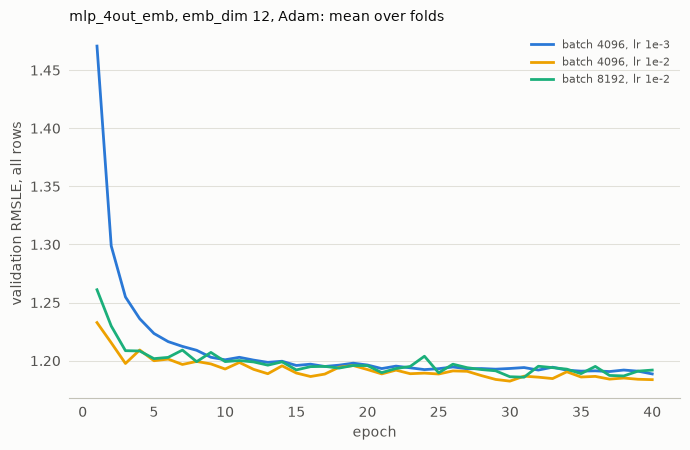

In [8]:
COLORS = dict(zip(SETUPS, ["#2a78d6", "#eda100", "#1baf7a"]))

fig, ax = plt.subplots(figsize=(7, 4.6), facecolor=SURFACE)
for label, color in COLORS.items():
    curve = pd.DataFrame(results[results.setup == label].val_curve.tolist()).mean()
    ax.plot(np.arange(1, len(curve) + 1), curve, color=color, lw=2, label=label)
ax.set(xlabel="epoch", ylabel="validation RMSLE, all rows")
ax.set_title(
    "mlp_4out_emb, emb_dim 12, Adam: mean over folds",
    loc="left",
    color=INK,
    fontsize=10,
)
style_axis(ax)
ax.legend(frameon=False, fontsize=8, labelcolor=TEXT)
plt.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")